# Phishing Website Classification: EDA and Modelling

## Part 1: Data and exploration (sections 1 to 6)

### 1. Load and inspect the data

The UCI Phishing Websites dataset is provided in ARFF format. I load it into a pandas DataFrame, convert the encoded values into integers, and standardise the column names to lowercase. I then inspect the dataset's dimensions, sample rows, missing values and feature-value ranges before preparing the target variable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

SEED = 1
DATA_PATH = "data/training-dataset.arff"

In [2]:
import sys

# Informational only. This notebook avoids nested parallelism (see section 9),
# so it does not depend on context-aware warnings.
print(sys.flags.context_aware_warnings)

0


In [3]:
# Load the data
raw, meta = arff.loadarff(DATA_PATH)
df = pd.DataFrame(raw)

In [4]:
# Decode byte strings to integers and normalize column names to lowercase
df = df.apply(lambda s: s.str.decode("utf-8")).astype(int)
df.columns = df.columns.str.lower()
df.shape

(11055, 31)

The dataset contains 11,055 rows and 31 columns. These comprise 30 original features and the `result` target column.

In [5]:
# Review features
df.head().T

,0,1,2,3,4
having_ip_address,-1,1,1,1,1
url_length,1,1,0,0,0
shortining_service,1,1,1,1,-1
having_at_symbol,1,1,1,1,1
double_slash_redirecting,-1,1,1,1,1
prefix_suffix,-1,-1,-1,-1,-1
having_sub_domain,-1,0,-1,-1,1
sslfinal_state,-1,1,-1,-1,1
domain_registeration_length,-1,-1,-1,1,-1
favicon,1,1,1,1,1


In [6]:
# Check for missing values
df.isna().sum().sum()

np.int64(0)

In [7]:
# Check the range of values
sorted(np.unique(df.values))

[np.int64(-1), np.int64(0), np.int64(1)]

The feature values are encoded as -1, 0 or 1. Their meanings depend on the individual feature, so the values should be interpreted using the dataset's feature definitions rather than assuming that the same value has the same meaning across all columns.

In [8]:
df.result.nunique()

2

In [9]:
# Check how many different values each column contains
# 23 columns have two distinct values
# 8 columns have three distinct values
df.nunique().value_counts()     

2    23
3     8
Name: count, dtype: int64

### 2. Define the target and check data quality

In [10]:
# Relabel the target: 1 = phishing, 0 = legitimate
df["phishing"] = (df.result == -1).astype(int)

# Remove the original target column
df = df.drop(columns="result")

The original `result` column uses -1 for phishing websites and 1 for legitimate websites. I create a binary target called `phishing`, where 1 represents phishing and 0 represents legitimate websites. The original target column is then removed to avoid retaining two versions of the target.

In [11]:
# Check for exact duplicate rows without removing them
n_dup = df.duplicated().sum()

print("Total rows:", len(df))
print("Exact duplicate rows:", n_dup)
print("Rows retained:", len(df))

# Check whether identical feature configurations have consistent target labels
features = [col for col in df.columns if col != "phishing"]
conflicts = df.groupby(features)["phishing"].nunique()

n_configurations = len(conflicts)
n_single_label = (conflicts == 1).sum()
n_conflicting = (conflicts > 1).sum()

print("\nFeature configuration summary:")
print("Total unique feature configurations:", n_configurations)
print("Configurations with a single consistent target label:", n_single_label)
print("Configurations with conflicting target labels:", n_conflicting)
print(
    "Percentage with conflicting labels:",
    round(n_conflicting / n_configurations * 100, 2), "%"
)

Total rows: 11055
Exact duplicate rows: 5206
Rows retained: 11055

Feature configuration summary:
Total unique feature configurations: 5785
Configurations with a single consistent target label: 5721
Configurations with conflicting target labels: 64
Percentage with conflicting labels: 1.11 %


**Duplicate and conflicting-label checks**

The dataset contains 11,055 rows. A check identified 5,206 exact duplicate rows across the recorded features and target. These rows were retained because identical feature values do not establish that two records represent the same website. Removing them could discard valid observations and change the dataset's class distribution.

A further check identified 5,785 unique feature configurations. Of these, 5,721 had a single consistent target label, while 64 had conflicting labels. Thus, 1.11% of unique feature configurations were associated with both phishing and legitimate labels. This suggests that the available features do not uniquely determine the target for every configuration.

These checks describe repeated rows and repeated feature configurations; they do not establish how many distinct websites are represented in the dataset.

### 3. Split the dataset

In [12]:
# Create training, validation and test sets
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df.phishing)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=SEED,
    stratify=df_full_train.phishing)

In [13]:
# Reset the indexes and check the sizes
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

len(df_train), len(df_val), len(df_test)

(6633, 2211, 2211)

I split the dataset 60/20/20 into training, validation and test sets, stratified on the phishing target so class proportions are preserved. The training set fits models, the validation set compares them at default settings, and the test set is reserved for the selected model. Because duplicate rows were kept, some validation and test rows have an identical feature vector in training (57.2% of validation rows). Section 11 tests how much this affects the scores.

In [14]:
for name, data in [
    ("Train", df_train),
    ("Validation", df_val),
    ("Test", df_test),
]:
    print(name, data.phishing.value_counts(normalize=True).round(3))

Train phishing
0    0.557
1    0.443
Name: proportion, dtype: float64
Validation phishing
0    0.557
1    0.443
Name: proportion, dtype: float64
Test phishing
0    0.557
1    0.443
Name: proportion, dtype: float64


In [15]:
# How many validation rows have an identical feature vector in the training set?
seen = set(map(tuple, df_train[features].values))
overlap = np.mean([tuple(r) in seen for r in df_val[features].values])
print(f"Validation rows with an identical feature vector in train: {overlap:.1%}")

Validation rows with an identical feature vector in train: 57.2%


### 4. Explore the relationships between features and phishing

In [16]:
# Check the proportion of phishing and legitimate websites in the training data
df_full_train.phishing.value_counts(normalize=True)

phishing
0    0.556988
1    0.443012
Name: proportion, dtype: float64

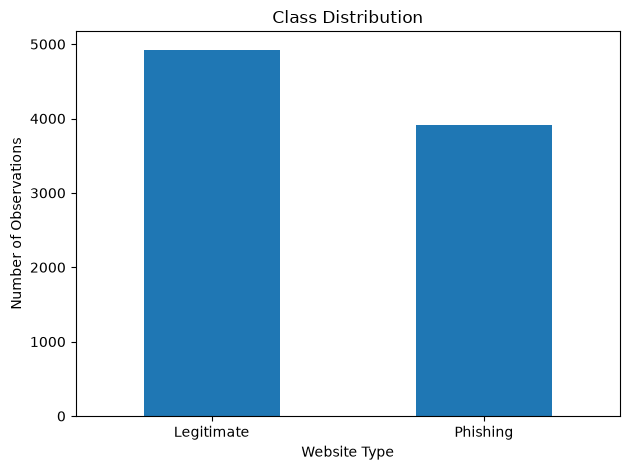

In [17]:
# Visualise the target distribution in the full training data (training plus validation)
class_counts = (
    df_full_train["phishing"]
    .map({0: "Legitimate", 1: "Phishing"})
    .value_counts()
    .reindex(["Legitimate", "Phishing"])
)

class_counts.plot(kind="bar", rot=0)
plt.title("Class Distribution")
plt.xlabel("Website Type")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [18]:
# Identify features with a highly dominant value in the training data
dominant = df_full_train[features].apply(
    lambda s: s.value_counts(normalize=True).max()).sort_values(ascending=False)
dominant.head(8)

rightclick                  0.957485
iframe                      0.909091
redirect                    0.885572
on_mouseover                0.881162
double_slash_redirecting    0.870194
shortining_service          0.868951
prefix_suffix               0.868159
port                        0.864202
dtype: float64

Several features have a dominant value, including `rightclick`, `iframe` and `redirect`. This indicates that their values are unevenly distributed. However, a dominant value does not necessarily make a feature uninformative; its relationship with the phishing target must be examined separately.

#### Compare phishing rates across all features

To explore the relationship between the features and the phishing target, I compared phishing rates across the possible values of each feature using the full training data (training plus validation). This provides an initial overview of which feature values are associated with higher or lower phishing rates. The table shows phishing rates rather than counts, so the number of observations for each value should also be considered when interpreting the results.

In [19]:
# How does the original classification vary depending on the features?

# Run the same groupby logic to collect the data
summary_data = []
for col in features:
    grouped = df_full_train.groupby(col)["phishing"].agg(["mean", "count"])

    for val, row in grouped.iterrows():
        summary_data.append({
            "feature": col,
            "feature_value": val,
            "phishing_rate": row["mean"],
            "count": row["count"]
        })

summary_df = pd.DataFrame(summary_data)

# Pivot the table so feature values become columns (-1, 0, 1)
pivoted_df = summary_df.pivot(
    index="feature",
    columns="feature_value",
    values="phishing_rate"
)

# Rename the columns to make them clearer
pivoted_df.columns = [
    f"phishing_rate_when_val_{col}"
    for col in pivoted_df.columns
]

pivoted_df = pivoted_df.reset_index()

# Sort by phishing rate when the feature value is -1
pivoted_df = pivoted_df.sort_values(
    by="phishing_rate_when_val_-1",
    ascending=False,
    na_position="last"
)

# Display the sorted table
print(pivoted_df.to_string(index=False))

                    feature  phishing_rate_when_val_-1  phishing_rate_when_val_0  phishing_rate_when_val_1
              url_of_anchor                   0.989366                  0.280499                  0.062087
             sslfinal_state                   0.856893                  0.980498                  0.111396
                web_traffic                   0.627551                  0.679786                  0.251836
              links_in_tags                   0.603547                  0.388123                  0.296765
               google_index                   0.596563                       NaN                  0.418394
                request_url                   0.595680                       NaN                  0.337665
          having_sub_domain                   0.546296                  0.627254                  0.194479
         statistical_report                   0.543200                       NaN                  0.426521
              prefix_suffix          

In [20]:
# Rank features by mutual information with the phishing target
mi = df_full_train[features].apply(
    lambda s: mutual_info_score(s, df_full_train.phishing)
).sort_values(ascending=False)
mi.head(8)

sslfinal_state       0.343894
url_of_anchor        0.332505
prefix_suffix        0.085060
web_traffic          0.084328
having_sub_domain    0.079384
request_url          0.032771
links_in_tags        0.031858
sfh                  0.026175
dtype: float64

The mutual information results identify `sslfinal_state` and `url_of_anchor` as the two features most strongly associated with the phishing target. `prefix_suffix`, `web_traffic` and `having_sub_domain` also rank relatively highly. Mutual information measures the association between each feature and the target, including relationships that may not be linear. These results provide a basis for examining the five features in more detail.

In [21]:
# Rank features by the absolute strength of their correlation with the target
corr = df_full_train[features].corrwith(df_full_train.phishing)
corr.sort_values(key=np.abs, ascending=False).head(8)

sslfinal_state                -0.713543
url_of_anchor                 -0.694254
web_traffic                   -0.351825
prefix_suffix                 -0.347544
having_sub_domain             -0.302887
request_url                   -0.255302
links_in_tags                 -0.243750
domain_registeration_length    0.227848
dtype: float64

The correlation results also place `sslfinal_state` and `url_of_anchor` at the top, with `web_traffic`, `prefix_suffix` and `having_sub_domain` showing relatively strong relationships with the target. Because the target is encoded as 1 for phishing and 0 for legitimate websites, negative correlations indicate that higher feature values tend to be associated with a lower phishing rate. The results should be interpreted in the context of each feature's encoding. Together, the pivot table, mutual information and correlation results support examining these five features in more detail.

#### Examine selected features in more detail

Based on the initial comparison of phishing rates, mutual information and correlation results, I selected `sslfinal_state`, `url_of_anchor`, `web_traffic`, `having_sub_domain` and `prefix_suffix` for closer examination. These features showed comparatively strong associations with the target across the exploratory analyses. I compared their phishing rates and observation counts to understand how the target distribution varies across their encoded values.

In [22]:
# Compare phishing rates across selected feature values
for col in ["sslfinal_state", "url_of_anchor", "web_traffic", "having_sub_domain", "prefix_suffix",]:
    print(df_full_train.groupby(col).phishing.agg(["mean", "count"]).round(3), "\n")

                 mean  count
sslfinal_state              
-1              0.857   2858
 0              0.980    923
 1              0.111   5063 

                mean  count
url_of_anchor              
-1             0.989   2633
 0             0.280   4246
 1             0.062   1965 

              mean  count
web_traffic              
-1           0.628   2156
 0           0.680   2058
 1           0.252   4630 

                    mean  count
having_sub_domain              
-1                 0.546   2700
 0                 0.627   2884
 1                 0.194   3260 

               mean  count
prefix_suffix             
-1             0.51   7678
 1             0.00   1166 



The phishing rate varies substantially across values of `sslfinal_state` and `url_of_anchor`. For `sslfinal_state`, the phishing rate is approximately 85.7% for value -1 and 98.0% for value 0, compared with 11.1% for value 1. For `url_of_anchor`, the corresponding rates are approximately 98.9%, 28.0% and 6.2%.

The other three features also show differences in phishing rates. For `web_traffic`, the rate ranges from approximately 25.2% for value 1 to 68.0% for value 0. For `having_sub_domain`, it ranges from 19.4% for value 1 to 62.7% for value 0. For `prefix_suffix`, the phishing rate is approximately 51% for value -1 and 0% for value 1.

These results show that the target distribution differs across the values of all five selected features. The observation counts provide useful context for these rates, although these exploratory comparisons do not by themselves establish how well the features will predict unseen data.

### 5. Exploratory Random Forest for feature importance

In [23]:
# Train a Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(df_train[features], df_train.phishing)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total 

In [24]:
# Rank features using the Random Forest's impurity-based importance
impurity = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
impurity.head(8)

sslfinal_state            0.299992
url_of_anchor             0.238965
web_traffic               0.085473
having_sub_domain         0.067188
links_in_tags             0.048109
prefix_suffix             0.046079
sfh                       0.020150
links_pointing_to_page    0.020061
dtype: float64

The Random Forest also assigns the highest impurity-based importance scores to `sslfinal_state` and `url_of_anchor`. `web_traffic`, `having_sub_domain`, `links_in_tags` and `prefix_suffix` contribute to the model as well. These scores reflect how much each feature contributes to reducing impurity across the fitted trees, but they should not be interpreted as causal effects.

In [25]:
# Measure the effect of shuffling each feature on validation-set performance
perm = permutation_importance(rf, df_val[features], df_val.phishing,
                              n_repeats=5, random_state=SEED, n_jobs=1)
perm = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)
perm.head(6)

url_of_anchor        0.122388
sslfinal_state       0.112528
prefix_suffix        0.031117
web_traffic          0.026232
having_sub_domain    0.023066
links_in_tags        0.019991
dtype: float64

Permutation importance measures how much the fitted model's validation performance decreases when the values of one feature are shuffled. Here, `url_of_anchor` and `sslfinal_state` have the largest mean importance scores, followed by `prefix_suffix`, `web_traffic`, `having_sub_domain` and `links_in_tags`. This supports the earlier exploratory findings, although the rankings can depend on the fitted model, the evaluation data and relationships between features.

### 6. Data findings

- Data quality: The dataset contains 11,055 rows, 30 original features and one target column, with no missing values. The features use encoded values of -1, 0 and 1. A check identified 5,206 exact duplicate rows, which were retained because the available evidence does not establish that they represent duplicate websites. Of 5,785 unique feature configurations, 64 had conflicting target labels, representing 1.11% of configurations. This highlights a limitation of the available features in distinguishing some records.

- Target definition: I converted the original result column into a binary phishing target, with 1 representing phishing websites and 0 representing legitimate websites. The original target column was then removed, leaving 30 input features.

- Data splitting: I used stratified splitting to create training, validation and test sets containing 60%, 20% and 20% of the observations, respectively. This preserves approximately the same phishing-to-legitimate class proportions across the sets. The test set remains reserved for the final evaluation of the selected model.

- Exploratory findings: The pivot table, mutual information and correlation analyses identified `sslfinal_state`, `url_of_anchor`, `web_traffic`, `having_sub_domain` and `prefix_suffix` as useful candidates for further examination. Their phishing rates varied across encoded feature values, with particularly pronounced differences for `sslfinal_state` and `url_of_anchor`.

- Model-based feature importance: The Random Forest's impurity-based importance and validation-set permutation importance both ranked `sslfinal_state` and `url_of_anchor` among the strongest features. `web_traffic`, `having_sub_domain` and `prefix_suffix` also ranked relatively highly, although their order differed between methods. These results provide additional evidence of their predictive usefulness in the fitted model, but feature importance does not establish causation.

- Modelling decision: I will retain all 30 features. Models are compared on the validation set at default settings, then tuned with stratified 5-fold cross-validation on the training plus validation data, scored by ROC AUC. The test set is used once, for the selected model. Because duplicate rows were kept, scores may be optimistic if duplicates are not distinct websites, so Section 11 repeats the comparison with duplicates removed and with identical feature vectors kept together.

## Part 2: Model training and selection (sections 7 to 12)

### 7. Evaluation setup

In [26]:
# Import tools for cross-validation, model selection and evaluation
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
# ROC AUC measures how well the model ranks phishing above
# legitimate websites, independently of a fixed classification threshold.
# Precision and recall use a threshold of 0.5 to assess the predictions.
# Phishing is the positive class (1).

Models are scored with ROC AUC (threshold-independent) plus precision, recall and F1 at a 0.5 threshold, with phishing as the positive class. Classes are close to balanced (44.3% phishing), so AUC is a reasonable headline metric, and precision and recall show the two error types: legitimate sites flagged as phishing (false positives) and phishing sites missed (false negatives). Section 8 compares models at default settings on the validation set. Section 9 tunes them with stratified 5-fold cross-validation on the training plus validation data. Section 10 scores the selected model once on the test set.

### 8. Baseline models (validation set)

In [27]:
def evaluate(model, X, y, name):
    # Get the predicted probability of phishing for each observation
    p = model.predict_proba(X)[:, 1]

    # Convert probabilities into binary predictions using a 0.5 threshold
    pred = (p >= 0.5).astype(int)

    # Return metrics for comparing model performance
    return {
        "model": name,
        "auc": roc_auc_score(y, p),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred)
    }

# Separate input features (X) from the phishing target (y)
X_train, y_train = df_train[features], df_train.phishing
X_val, y_val = df_val[features], df_val.phishing

# Combine training and validation data for later tuning and refitting
X_full, y_full = df_full_train[features], df_full_train.phishing

# Keep the test data separate for the final evaluation
X_test, y_test = df_test[features], df_test.phishing

models = {
  "Majority class": DummyClassifier(strategy="prior"),
  "Logistic regression (raw)": LogisticRegression(max_iter=2000),
  "Logistic regression (one-hot)": make_pipeline(OneHotEncoder(handle_unknown="ignore"),
                                                 LogisticRegression(max_iter=2000)),
  "Decision tree (default)": DecisionTreeClassifier(random_state=SEED),
}

# Fit each baseline model on training data and compare on validation data
# The test set is not used during this initial model comparison
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append(evaluate(m, X_val, y_val, name))
rows.append(evaluate(rf, X_val, y_val, "Random forest (default)"))   # rf from Section 5
pd.DataFrame(rows).round(3)

,model,auc,precision,recall,f1
0,Majority class,0.500,0.000,0.000,0.000
1,Logistic regression (raw),0.979,0.934,0.901,0.917
2,Logistic regression (one-hot),0.986,0.942,0.919,0.931
3,Decision tree (default),0.973,0.958,0.958,0.958
4,Random forest (default),0.996,0.980,0.959,0.970


The two logistic regressions show why one-hot matters. The features are categories coded -1/0/1, not quantities, so the raw version assumes a 0 sits “between” -1 and 1. In this run the one-hot version scored slightly higher (AUC 0.986 vs 0.979).

The majority-class baseline gives an AUC of 0.5, so every real model has learned something. The default random forest scored highest on validation (AUC 0.996, F1 0.970), ahead of the one-hot logistic regression (0.986, 0.931) and the default decision tree (0.973, 0.958). Because 57.2% of validation rows have an identical vector in the training set, flexible models such as trees may look better here than they would on unseen configurations. Section 11 tests this.

### 9. Hyperparameter tuning (5-fold CV)

In [28]:
# Use five stratified folds so each fold has a similar class distribution
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Define each model and the hyperparameter values to try
# GridSearchCV will compare every specified parameter combination
searches = {
  "Logistic regression (one-hot)": (
      make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(max_iter=2000)),
      {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
  "Decision tree": (DecisionTreeClassifier(random_state=SEED),
      {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [1, 5, 10, 20]}),
    "Random forest": (RandomForestClassifier(random_state=SEED),
      {"n_estimators": [200], "max_depth": [10, 20, None],
       "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5]}),
}

# Parallelise at one level only: GridSearchCV(n_jobs=-1) below.
# The models stay single-threaded, because nested parallelism triggers a
# scikit-learn false-alarm warning (scikit-learn issue #35089).
searches["XGBoost"] = (XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=1),
    {"n_estimators": [200, 400], "max_depth": [3, 5, 8], "learning_rate": [0.05, 0.1, 0.3]})

best, summ = {}, []

for name, (est, grid) in searches.items():
    
    # Test the parameter combinations using five-fold cross-validation.
    # ROC AUC is the score used to select the best parameter combination.
    gs = GridSearchCV(
        est, grid, scoring="roc_auc", cv=cv, n_jobs=-1
    ).fit(X_full, y_full)

    # Save the estimator configured with the best parameters
    best[name] = gs.best_estimator_

    # Evaluate the selected configuration using cross-validation metrics
    r = cross_validate(
        gs.best_estimator_, X_full, y_full, cv=cv,
        scoring=["roc_auc", "precision", "recall", "f1"]
    )

    # Store the mean scores and ROC AUC variation for comparison
    summ.append({
        "model": name,
        "cv_auc": r["test_roc_auc"].mean(),
        "auc_std": r["test_roc_auc"].std(),
        "precision": r["test_precision"].mean(),
        "recall": r["test_recall"].mean(),
        "f1": r["test_f1"].mean(),
        "best_params": gs.best_params_
    })

# Rank models by mean cross-validation ROC AUC
summary = pd.DataFrame(summ).sort_values("cv_auc", ascending=False)

summary.drop(columns="best_params").round(4)

,model,cv_auc,auc_std,precision,recall,f1
3,XGBoost,0.9964,0.0009,0.9701,0.9617,0.9659
2,Random forest,0.9961,0.0009,0.9741,0.9574,0.9656
0,Logistic regression (one-hot),0.9866,0.0009,0.9393,0.9239,0.9315
1,Decision tree,0.9846,0.0023,0.9373,0.9257,0.9314


Each model was tuned by grid search with stratified 5-fold cross-validation on the training plus validation data, scored by ROC AUC. The grids are in the code cell. XGBoost had the highest mean CV AUC (0.9964), but the random forest was effectively tied (0.9961). The 0.0003 gap is smaller than the fold-to-fold standard deviation (0.0009), so the CV scores do not separate them. Both clearly outperformed the logistic regression (0.9866) and decision tree (0.9846).

### Methodology Note: Evaluation Consideration
GridSearchCV selects the parameters using all of X_full, after which cross_validate evaluates those already-selected parameters on the same data and folds. Consequently, the reported cross-validation metrics are not fully independent of hyperparameter selection.

Nested cross-validation could be a more rigorous comparison. It performs parameter selection inside each outer training fold. Alternatively, reporting gs.best_score_ as the tuning score, labelling the other cross-validation metrics as exploratory, and retaining the separate test evaluation.

### 10. Final model on the test set

In [29]:
# Select the model with the highest mean cross-validation ROC AUC
leader = summary.iloc[0].model

# Refit the selected model on all training and validation observations
final = best[leader].fit(X_full, y_full)

# Evaluate the model once on the untouched test set
print(evaluate(final, X_test, y_test, leader))

# Display counts in the order [[true negatives, false positives],
#                              [false negatives, true positives]]
print(confusion_matrix(y_test, final.predict(X_test)))   # [[TN FP],[FN TP]]

{'model': 'XGBoost', 'auc': 0.99735613985643, 'precision': 0.9722792607802875, 'recall': 0.9663265306122449, 'f1': 0.9692937563971341}
[[1204   27]
 [  33  947]]


I fixed the selection rule before looking at the test set: the model with the highest mean CV AUC is refit on the training plus validation data and scored once on the test set. That model is XGBoost. On the 2,211 test rows it scored AUC 0.997, precision 0.972, recall 0.966 and F1 0.969. It made 27 false positives (legitimate sites flagged) and 33 false negatives (phishing sites missed). I did not retune after this step.

### 11. Sensitivity to duplicate rows

In [30]:
def make_split(d, how):

    # Protocol 1: retain all rows, including exact duplicates.
    # Protocol 2: remove exact duplicate rows before splitting.
    if how == "dedupe":
        d = d.drop_duplicates()
        
    d = d.reset_index(drop=True)

    # Protocol 3: keep identical feature configurations in the same
    # group so they cannot appear in both training and test sets.    
    if how == "group":                      # identical feature vectors stay together
        groups = d.groupby(features).ngroup()
        tr, te = next(
            StratifiedGroupKFold(
                5, shuffle=True, random_state=SEED
            ).split(d, d.phishing, groups=groups)
        )
    else:
        # Use a stratified random split for the other two protocols
        tr, te = train_test_split(
            np.arange(len(d)), test_size=0.2,
            random_state=SEED, stratify=d.phishing
        )
        
    return d.iloc[tr].reset_index(drop=True), d.iloc[te].reset_index(drop=True)

# Repeat the model comparison under three data-splitting protocols
results = []

for how in ["random", "dedupe", "group"]:
    train_part, test_part = make_split(df, how)

    # Measure how many test feature configurations also occur in training
    seen = set(map(tuple, train_part[features].values))
    overlap = np.mean([
        tuple(r) in seen for r in test_part[features].values
    ])

    # Use grouped cross-validation only for the grouped protocol
    if how == "group":
        groups = train_part.groupby(features).ngroup()
        cv_p = StratifiedGroupKFold(
            5, shuffle=True, random_state=SEED
        )
    else:
        groups, cv_p = None, StratifiedKFold(
            5, shuffle=True, random_state=SEED
        )

    # Tune each model on the training portion, then evaluate on held-out data
    for name, (est, grid) in searches.items():
        gs = GridSearchCV(est, grid, scoring="roc_auc", cv=cv_p, n_jobs=-1)
        gs.fit(train_part[features], train_part.phishing, groups=groups)
        p = gs.best_estimator_.predict_proba(test_part[features])[:, 1]
        pred = (p >= 0.5).astype(int)
        results.append({"protocol": how, "model": name, "train_rows": len(train_part),
                        "test_overlap": round(overlap, 3), "cv_auc": round(gs.best_score_, 4),
                        "test_auc": round(roc_auc_score(test_part.phishing, p), 4),
                        "precision": round(precision_score(test_part.phishing, pred), 3),
                        "recall": round(recall_score(test_part.phishing, pred), 3)})
pd.DataFrame(results)

,protocol,model,train_rows,test_overlap,cv_auc,test_auc,precision,recall
0,random,Logistic regression (one-hot),8844,0.637,0.9866,0.9878,0.935,0.923
1,random,Decision tree,8844,0.637,0.9846,0.9814,0.912,0.940
2,random,Random forest,8844,0.637,0.9961,0.9966,0.968,0.968
3,random,XGBoost,8844,0.637,0.9964,0.9974,0.972,0.966
4,dedupe,Logistic regression (one-hot),4679,0.021,0.9865,0.9835,0.942,0.914
5,dedupe,Decision tree,4679,0.021,0.9757,0.9758,0.926,0.927
6,dedupe,Random forest,4679,0.021,0.9898,0.9867,0.947,0.919
7,dedupe,XGBoost,4679,0.021,0.9930,0.9897,0.940,0.937
8,group,Logistic regression (one-hot),8843,0.000,0.9848,0.9885,0.947,0.920
9,group,Decision tree,8843,0.000,0.9795,0.9762,0.912,0.945


### 12. Conclusions and limitations

**Conclusions**

The analysis explored the UCI Phishing Websites dataset and compared four classification models: logistic regression with one-hot encoding, a decision tree, a random forest and XGBoost. Exploratory analysis identified `sslfinal_state` and `url_of_anchor` as particularly informative features. Their relationships with the phishing target were also supported by the Random Forest feature-importance results.

XGBoost achieved the highest mean cross-validation ROC AUC of 0.9964, although the random forest performed almost as well at 0.9961. On the reserved test set, XGBoost achieved a ROC AUC of 0.9974, precision of 0.9723, recall of 0.9663 and F1 score of 0.9693. At the 0.5 classification threshold, it correctly identified 947 phishing observations and missed 33, while incorrectly flagging 27 legitimate observations.

The duplicate-sensitivity experiment provided an additional check on these results. XGBoost achieved a test ROC AUC of 0.9897 when exact duplicate rows were removed and 0.9952 when identical feature configurations were kept together across the training and test sets. Although these scores were lower than the original result, they remained high. This suggests that the model's performance is not explained solely by repeated feature configurations, while also showing why the original evaluation should be interpreted with caution.

**Limitations**

- **Duplicate observations and data leakage:** The original dataset contains 5,206 exact duplicate rows, and many validation and test observations share feature configurations with the training data. These overlaps can make evaluation scores more optimistic than performance on previously unseen feature configurations. The sensitivity analysis helps assess this issue, but identical feature vectors do not establish whether records represent the same website.

- **Conflicting labels:** Of the 5,785 unique feature configurations, 64 (1.11%) have both phishing and legitimate labels. This indicates that the recorded features do not uniquely determine the target for every configuration, placing a limit on what a model can learn from these inputs.

- **Dataset scope:** The analysis uses the supplied dataset and its 30 encoded features. The results do not establish how well the model would perform on newer websites, different data sources or phishing techniques not represented in the dataset.

- **Model selection and evaluation:** ROC AUC was used to select hyperparameters, while precision, recall and F1 were evaluated at a fixed threshold of 0.5. Different operational priorities or thresholds could change the balance between false positives and missed phishing websites. In addition, the cross-validation results should be interpreted with care because the selected hyperparameters were evaluated again on the same data used during tuning.

Overall, XGBoost was the strongest model in this comparison, but its high scores should be treated as evidence of performance on this dataset rather than a guarantee of real-world phishing detection accuracy. Further evaluation on independently collected, previously unseen websites would be needed to assess its practical usefulness.

In [31]:
import sys
import sklearn
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Context-aware warnings:", sys.flags.context_aware_warnings)

Python: 3.14.5 (main, Jun  2 2026, 22:25:17) [Clang 22.1.3 ]
scikit-learn: 1.9.1
joblib: 1.6.0
Context-aware warnings: 0
